In [1]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

In [2]:
def preprocess_data(file):
    party_converter = lambda party: 1 if party == b'republican' else -1
    vote_converter = lambda vote: 1 if vote == b'y' else -1 if vote == b'n' else 0
    converters = { 0: party_converter }
    for col in np.arange(1, 17):
        converters[col] = vote_converter
    return np.loadtxt(file, delimiter=',', converters=converters)

In [3]:
def fit(X, k):
    n, d = X.shape
    idx = np.random.permutation(n)
    centroids = X[idx[:k]]
    labels = np.zeros((n, 1))
    X_norm = np.sum(np.square(X), axis=1, keepdims=True)
    for epoch in range(100):
        distances = X_norm + np.sum(np.square(centroids), axis=1, keepdims=False) - (2 * X @ centroids.T)
        labels = np.argmin(distances, axis=1, keepdims=True)
        means = np.zeros((k, d))
        for j in range(k):
            mask = (labels == j).flatten()
            if np.any(mask):
                means[j] = X[mask].mean(axis=0) 
            else:
                means[j] = centroids[j]
        if np.linalg.norm(centroids - means) <= 1e-12:
            break
        centroids = means
    distances = X_norm + np.sum(np.square(centroids), axis=1, keepdims=False) - (2 * X @ centroids.T)
    labels = np.argmin(distances, axis=1, keepdims=True)
    return centroids, labels

In [4]:
def plot_k_means_failure(X):
    _, naive_labels = fit(X, 2)
    model = TSNE(n_components=2, random_state=0)
    X_embedded = model.fit_transform(X)
    x_values = X_embedded[:, 0]
    y_values = X_embedded[:, 1]
    plt.scatter(x_values, y_values, c=naive_labels, cmap='viridis')
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.title("Why k-Means Fails: Naive Clusters on 16D Data")
    plt.savefig("kMeans_failure.png")
    plt.show()

In [5]:
def build_weight_function(X, sigma):
    diff = X[None, :, :] - X[:, None, :]
    norm = np.linalg.norm(diff, axis=2)
    W = np.exp(-(norm**2 / (2 * sigma**2)))
    W[np.arange(W.shape[0]), np.arange(W.shape[0])] = 0.0
    return W

In [6]:
def build_degree(W):
    return np.diag(np.sum(W, axis=1))

In [7]:
def build_laplacian_embedding(X, sigma):
    W = build_weight_function(X, sigma)
    D = build_degree(W)
    L = D - W
    eigen_val, eigen_vec = np.linalg.eigh(L)
    return eigen_vec

In [8]:
def build_fiedler_vector(X, sigma):
    return build_laplacian_embedding(X, sigma)[:, 1]

In [9]:
def clustering_accuracy(X, y, sigma):
    m, n = X.shape
    q1 = build_fiedler_vector(X, sigma)
    y_hat = np.sign(q1)[:]
    assert y.shape == y_hat.shape
    misclassified = min(np.sum(y != y_hat), np.sum(y == y_hat))
    return (1 - (1.0 / m) * misclassified)

In [10]:
def solve_normal_equation(A, b):
    at_a = A.T @ A
    at_b = A.T @ b
    return np.linalg.inv(at_a) @ at_b

In [11]:
def regression_accuracy(X, y, sigma, M, J):
    laplacian_embedding = build_laplacian_embedding(X, sigma)[:, :M]
    A = laplacian_embedding[:J, :]
    b = y[:J]
    beta_hat = solve_normal_equation(A, b)
    y_hat = np.sign(laplacian_embedding @ beta_hat)
    misclassified = np.sum(y != y_hat)
    return (1 - (1.0 / 435) * misclassified)

In [12]:
def plot_clustering_accuracy(sigmas, accuracies):
    plt.figure(figsize=(8, 6))
    plt.plot(sigmas, accuracies)
    plt.title("Spectral clustering accuracy")
    plt.xlabel("Sigma")
    plt.ylabel("Clustering accuracy")
    plt.savefig('clustering_accuracy.png')
    plt.show()

0.8781609195402299


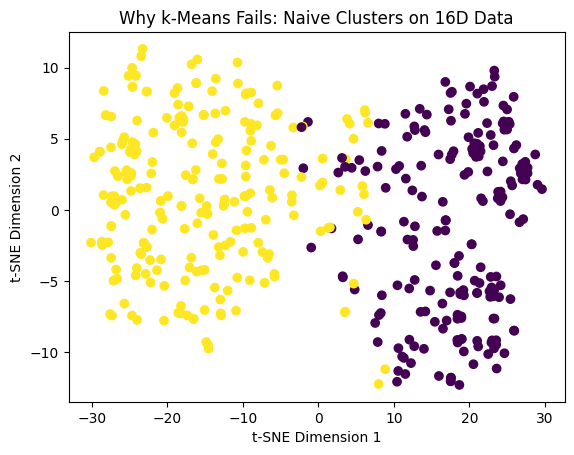

max accuracy: 0.8804597701149426 at sigma: 2.1


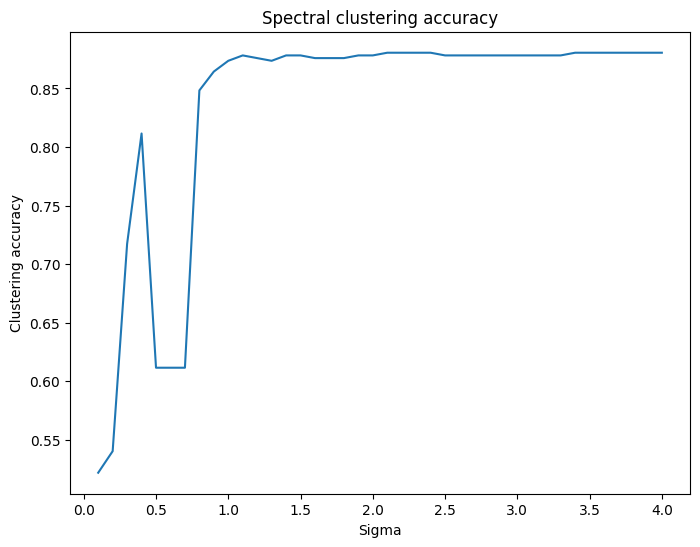

M: 2, J: 5, accuracy:0.8735632183908046
M: 2, J: 10, accuracy:0.8735632183908046
M: 2, J: 20, accuracy:0.8781609195402299
M: 2, J: 40, accuracy:0.8758620689655172
M: 3, J: 5, accuracy:0.8988505747126436
M: 3, J: 10, accuracy:0.871264367816092
M: 3, J: 20, accuracy:0.8804597701149426
M: 3, J: 40, accuracy:0.8781609195402299
M: 4, J: 5, accuracy:0.39540229885057476
M: 4, J: 10, accuracy:0.9149425287356322
M: 4, J: 20, accuracy:0.8988505747126436
M: 4, J: 40, accuracy:0.8919540229885058
M: 5, J: 5, accuracy:0.4114942528735632
M: 5, J: 10, accuracy:0.7494252873563219
M: 5, J: 20, accuracy:0.8505747126436782
M: 5, J: 40, accuracy:0.864367816091954
M: 6, J: 5, accuracy:0.6413793103448275
M: 6, J: 10, accuracy:0.8183908045977011
M: 6, J: 20, accuracy:0.8942528735632184
M: 6, J: 40, accuracy:0.8620689655172413


In [13]:
data = preprocess_data('datasets/house-votes-84.data')
X, y = data[:,1:], data[:, 0]

_, labels = fit(X, 2)
y_hat = labels.reshape(-1)
y_prime = (y > 0).astype(int)
misclassified = min(np.sum(y_hat != y_prime), np.sum(y_hat == y_prime))
accuracy = (1 - (1.0 / 435) * misclassified)
print(accuracy)

plot_k_means_failure(X)

sigmas, accuracies = np.arange(0.1, 4.1, 0.1), []
for sigma in sigmas:
    accuracies.append(clustering_accuracy(X, y, sigma))
max_accuracy = np.max(accuracies)
max_sigma = sigmas[np.argmax(accuracies)]
print(f'max accuracy: {max_accuracy} at sigma: {max_sigma}')
plot_clustering_accuracy(sigmas, accuracies)

accuracies = []
Ms = [2, 3, 4, 5, 6]
Js = [5, 10, 20, 40]
for M in Ms:
    for J in Js:
        accuracies.append(regression_accuracy(X, y, max_sigma, M, J))
for m_idx, M in enumerate(Ms):
    for j_idx, J in enumerate(Js):
        print(f'M: {M}, J: {J}, accuracy:{accuracies[4 * m_idx + j_idx]}')

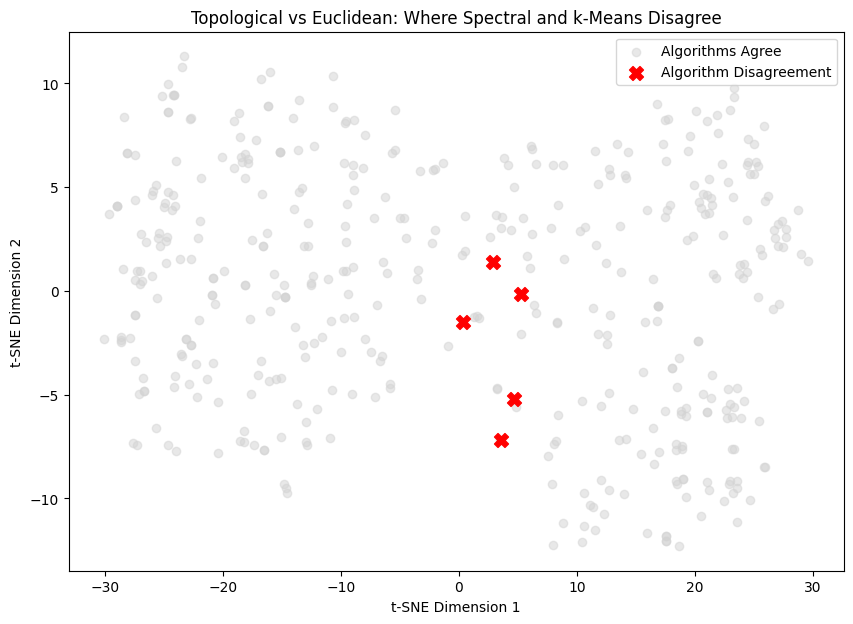

k-Means correct on battleground: 2 / 5
Spectral correct on battleground: 3 / 5


In [14]:
def plot_algorithm_disagreement(X, y_kmeans, y_spectral):
    model = TSNE(n_components=2, random_state=0)
    X_embedded = model.fit_transform(X)
    y_k = y_kmeans.flatten()
    y_s = y_spectral.flatten()
    disagree_mask = (y_k != y_s)
    agree_mask = (y_k == y_s)
    
    plt.figure(figsize=(10, 7))
    plt.scatter(X_embedded[agree_mask, 0], X_embedded[agree_mask, 1], 
                c='lightgray', alpha=0.5, label='Algorithms Agree')
    plt.scatter(X_embedded[disagree_mask, 0], X_embedded[disagree_mask, 1], 
                c='red', marker='X', s=100, label='Algorithm Disagreement')    
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.title("Topological vs Euclidean: Where Spectral and k-Means Disagree")
    plt.legend()
    plt.show()

    true_battleground = y[disagree_mask]
    k_battleground = y_k[disagree_mask]
    s_battleground = y_s[disagree_mask]
    print(f"k-Means correct on battleground: {np.sum(true_battleground == k_battleground)} / {len(true_battleground)}")
    print(f"Spectral correct on battleground: {np.sum(true_battleground == s_battleground)} / {len(true_battleground)}")
    
_, labels = fit(X, 2)
y_k = labels.reshape(-1)
y_k = np.where(y_k == 0, -1, 1)
q1 = build_fiedler_vector(X, 2.1)
y_s = np.sign(q1)[:]
if np.sum(y_k == y_s) < (len(y_k) / 2):
    y_s = -y_s
plot_algorithm_disagreement(X, y_k, y_s)

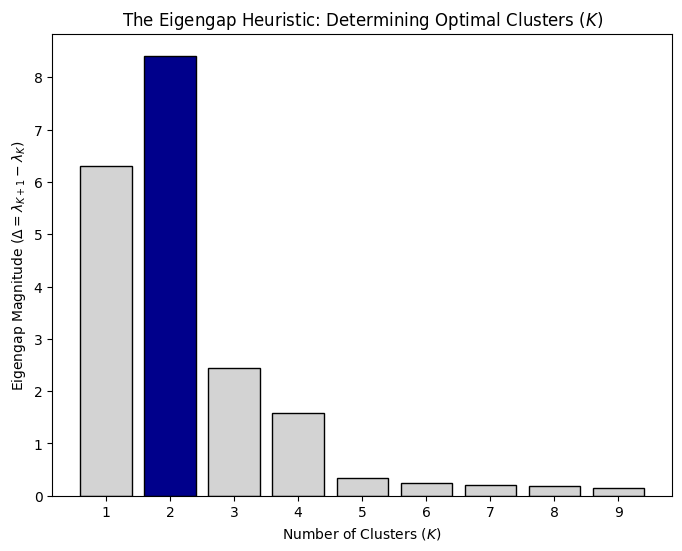

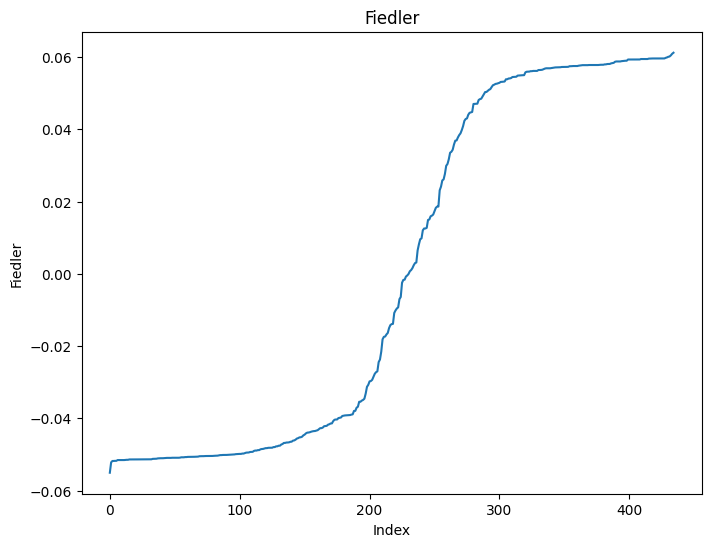

In [15]:
W = build_weight_function(X, 2.1)
D = build_degree(W)
L = D - W
eigen_val, eigen_vec = np.linalg.eigh(L)
first_10_eigenvals = eigen_val[:10]
eigen_gaps = np.diff(first_10_eigenvals)
plt.figure(figsize=(8, 6))
K_values = np.arange(1, 10)
colors = ['lightgray'] * len(K_values)
colors[1] = 'darkblue'
plt.bar(K_values, eigen_gaps, color=colors, edgecolor='black')
plt.title("The Eigengap Heuristic: Determining Optimal Clusters ($K$)")
plt.xlabel("Number of Clusters ($K$)")
plt.ylabel("Eigengap Magnitude ($\\Delta = \\lambda_{K+1} - \\lambda_K$)")
plt.xticks(K_values)
plt.savefig("optimal_clusters.png")
plt.show()

fiedler = eigen_vec[:, 1]
fiedler.sort()
plt.figure(figsize=(8, 6))
plt.plot(np.arange(0, 435, 1), fiedler)
plt.title("Fiedler")
plt.xlabel("Index")
plt.ylabel("Fiedler")
plt.show()